# Delivery Time Prediction

**Assignment:** Simple Linear Regression  
**Author:** Akash Jain

## 1. Objective
Predict **Delivery Time** using **Sorting Time**. The workflow includes data loading, EDA, model development, model evaluation and predictions.

## 2. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 3. Load and inspect the dataset

In [2]:
df = pd.read_csv("Dataset\delivery_time.csv")
display(df.head())
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

,Delivery Time,Sorting Time
0,21.00,10
1,13.50,4
2,19.75,6
3,24.00,9
4,29.00,10


Shape: (21, 2)

Data types:
Delivery Time    float64
Sorting Time       int64
dtype: object

Missing values:
Delivery Time    0
Sorting Time     0
dtype: int64

Duplicate rows: 0


## 4. Exploratory Data Analysis (EDA)

In [3]:
display(df.describe())
num_col = df.select_dtypes(include='number')
print("\nCorrelation:\n", num_col.corr())

,Delivery Time,Sorting Time
count,21.000000,21.000000
mean,16.790952,6.190476
std,5.074901,2.542028
min,8.000000,2.000000
25%,13.500000,4.000000
50%,17.830000,6.000000
75%,19.750000,8.000000
max,29.000000,10.000000



Correlation:
                Delivery Time  Sorting Time
Delivery Time       1.000000      0.825997
Sorting Time        0.825997      1.000000


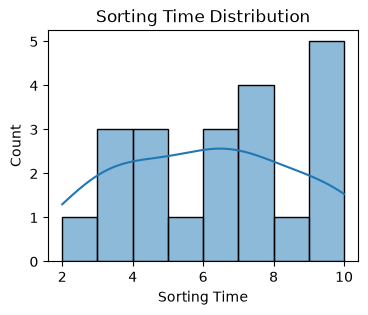

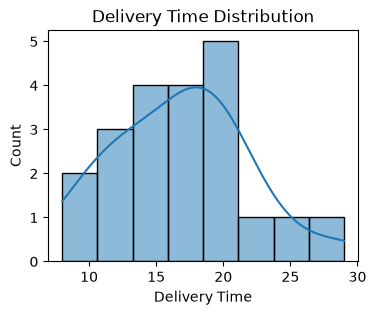

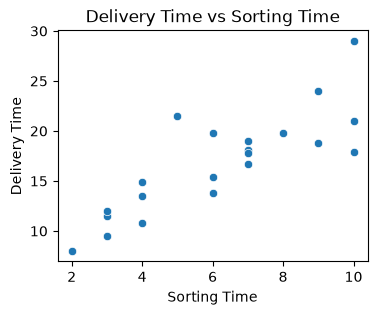

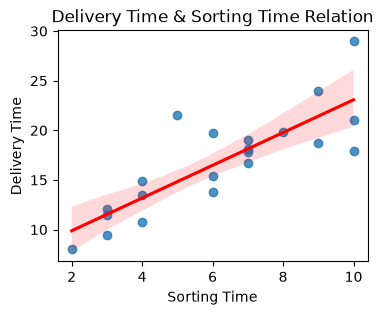

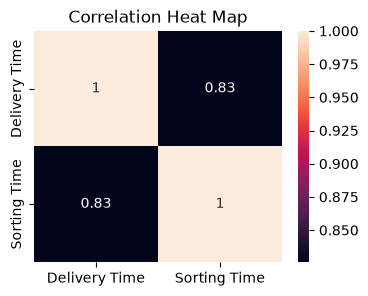

<Figure size 640x480 with 0 Axes>

In [4]:
plt.figure(figsize=(4, 3))
sns.histplot(df["Sorting Time"], bins=8, edgecolor="black", kde=True)
plt.title("Sorting Time Distribution")
plt.show()

plt.figure(figsize=(4, 3))
sns.histplot(df["Delivery Time"], bins=8, edgecolor="black", kde=True,)
plt.title("Delivery Time Distribution")
plt.show()

plt.figure(figsize=(4, 3))
sns.scatterplot(df, x= 'Sorting Time', y= 'Delivery Time')
plt.title("Delivery Time vs Sorting Time")
plt.show()

plt.figure(figsize=(4, 3))
sns.regplot(df, x= 'Sorting Time', y= 'Delivery Time', line_kws={'color': 'red'})
plt.title("Delivery Time & Sorting Time Relation")
plt.show()

plt.figure(figsize=(4, 3))
corr = num_col.corr()
sns.heatmap(corr, annot=True)
plt.title("Correlation Heat Map")
plt.show()

plt.tight_layout()
plt.show()

## 5. Train the selected model on the full dataset

In [5]:
X = df[["Sorting Time"]]
y = df["Delivery Time"]

model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[1.65]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Sorting Time']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6.583
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


## 6. Check model equation

In [6]:
print("Interception (c):", round(model.intercept_, 2))
print("Slope (m):", round(model.coef_[0], 2))

print('\n')
print(f'The Equation is :\n  y = {round(model.coef_[0], 2)}*X + {round(model.intercept_, 2)}')

Interception (c): 6.58
Slope (m): 1.65


The Equation is :
  y = 1.65*X + 6.58


## 7. Predict existing dataset values

In [7]:
y_pred = model.predict(X)

comparison = pd.DataFrame({
    'Actual Delivery Time': y,
    'Predicted Delivery Time': y_pred
})

print(comparison)

    Actual Delivery Time  Predicted Delivery Time
0                  21.00                23.072933
1                  13.50                13.178814
2                  19.75                16.476853
3                  24.00                21.423913
4                  29.00                23.072933
5                  15.35                16.476853
6                  19.00                18.125873
7                   9.50                11.529794
8                  17.90                23.072933
9                  18.75                21.423913
10                 19.83                19.774893
11                 10.75                13.178814
12                 16.68                18.125873
13                 11.50                11.529794
14                 12.03                11.529794
15                 14.88                13.178814
16                 13.75                16.476853
17                 18.11                18.125873
18                  8.00                 9.880774


## 8. Evaluate model

In [8]:
import numpy as np
print("MAE(mean absolute error):", mean_absolute_error(y, y_pred))

print("MSE(mean squared error):", mean_squared_error(y, y_pred))

print("RMSE:", np.sqrt(mean_squared_error(y, y_pred)))

print("R2 Score:", r2_score(y, y_pred))

MAE(mean absolute error): 2.0857409551882657
MSE(mean squared error): 7.793311548584062
RMSE: 2.7916503270617654
R2 Score: 0.6822714748417231


## 9. Visualise regression line

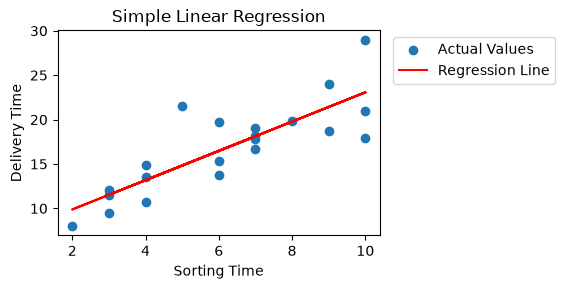

In [9]:
plt.figure(figsize=(4, 3))
plt.scatter(X, y, label='Actual Values')

plt.plot(X, y_pred, color='red', label='Regression Line')

plt.xlabel('Sorting Time')
plt.ylabel('Delivery Time')
plt.legend()
plt.title('Simple Linear Regression')
plt.tight_layout()
plt.legend(bbox_to_anchor = (1.02,1), loc= 'upper left')

## 10. Predict three new values

In [10]:
new_data = pd.DataFrame({'Sorting Time': [3, 11, 12]})

predictions = model.predict(new_data)

output = pd.DataFrame({
    'Sorting Time': new_data['Sorting Time'],
    'Predicted Delivery Time': predictions
})

display(output)

,Sorting Time,Predicted Delivery Time
0,3,11.529794
1,11,24.721953
2,12,26.370973


## 11. Export prediction CSV

In [11]:
output.to_csv('Dataset\Delivery_Time_Predictions.csv', index=False)

print("CSV file saved successfully!")

CSV file saved successfully!
